# Class-conditional neuron Shapley values

One game per class: $v_c(S)$ is the negative mean loss on the validation images of class $c$ when only the fc1 neurons in $S$ are active. The value $\phi_{i,c}$ says how much neuron $i$ contributes to recognising class $c$. The ten games are evaluated along the same orderings, so they share the cost of a single estimate.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import torch
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

from shapley_pruning.data import CLASSES, load_cifar10
from shapley_pruning.pruning import to_mask, top_k
from shapley_pruning.shapley import negative_loss_per_class, neuron_game, permutation_shapley
from shapley_pruning.training import get_parent, predict

In [2]:
data = load_cifar10()
parent = get_parent(data)
estimate = permutation_shapley(neuron_game(parent, data.val, payoff=negative_loss_per_class),
                               n_permutations=500)
class_phi = estimate.values  # (128 neurons, 10 classes)

## 1. What the mean value of a class measures

Efficiency holds in every class game, $\sum_i \phi_{i,c} = v_c(N) - v_c(\varnothing)$. The mean Shapley value of a class over the 128 neurons is therefore $\big(v_c(N) - v_c(\varnothing)\big)/128$: it depends only on the loss of that class with every neuron and with none, and says nothing about how many neurons the class needs. A class has a large total when the network recognises it well and the empty network's constant prediction does not favour it.

In [3]:
val_accuracy = [100 * (predict(parent, data.val)[data.val.labels == c] == c).float().mean().item()
                for c in range(10)]
efficiency = pd.DataFrame({
    "v_c(∅)": estimate.empty_value.numpy(),
    "v_c(N)": estimate.full_value.numpy(),
    "Σ_i φ_ic": class_phi.sum(0).numpy(),
    "validation accuracy (%)": val_accuracy,
}, index=CLASSES)
efficiency.sort_values("Σ_i φ_ic", ascending=False).round(3)

,v_c(∅),v_c(N),Σ_i φ_ic,validation accuracy (%)
automobile,-2.477,-0.522,1.955,83.922
airplane,-2.400,-0.698,1.702,78.669
horse,-2.282,-0.650,1.632,77.660
frog,-2.401,-0.778,1.623,75.600
dog,-2.413,-0.845,1.568,72.246
truck,-2.204,-0.664,1.540,80.769
ship,-2.120,-0.624,1.497,80.600
deer,-2.202,-0.936,1.266,70.916
bird,-2.242,-1.520,0.722,48.024
cat,-2.345,-1.666,0.679,36.149


The class totals follow how well each class is recognised: cat (36% validation accuracy) and bird (48%) have the smallest, automobile (84%) the largest. Where the two orders differ, the empty network explains it: its constant prediction favours ship and truck ($v_c(\varnothing)$ closest to 0), so they gain less from the neurons than their accuracy suggests. The totals do not measure how many neurons a class depends on.

## 2. Additivity

The global value of the neuron notebook is the mean loss over all validation images, a weighted sum of the class games: $v = \sum_c p_c\, v_c$ with $p_c$ the share of class $c$. By additivity, $\phi_i(v) = \sum_c p_c\, \phi_{i,c}$, and on the same orderings the identity holds sample by sample.

In [4]:
shares = torch.bincount(data.val.labels).float() / len(data.val.labels)
global_phi = permutation_shapley(neuron_game(parent, data.val), n_permutations=500).values
print(f"largest |φ_i − Σ_c p_c φ_ic|: {(global_phi - class_phi @ shares).abs().max():.1e}")

largest |φ_i − Σ_c p_c φ_ic|: 1.1e-07


## 3. Which neurons serve which classes

The 32 neurons with the largest global Shapley values, by decreasing value.

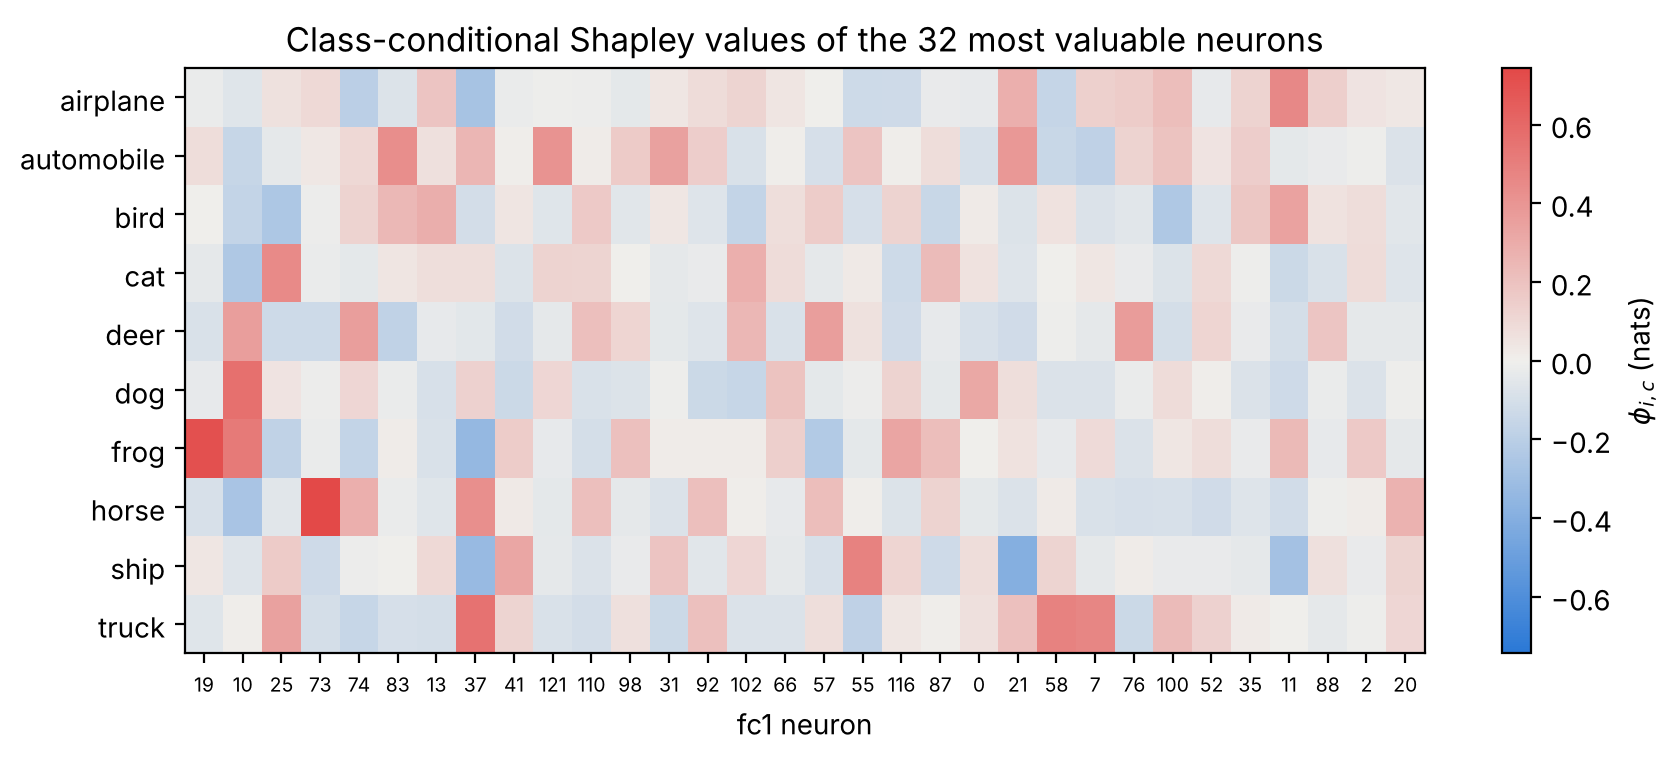

In [5]:
order = global_phi.argsort(descending=True)[:32]
diverging = LinearSegmentedColormap.from_list("diverging", ["#2a78d6", "#f0efec", "#e34948"])
limit = class_phi[order].abs().max().item()

fig, ax = plt.subplots(figsize=(10, 3.8))
image = ax.imshow(class_phi[order].T, cmap=diverging, norm=TwoSlopeNorm(0, -limit, limit), aspect="auto")
ax.set_xticks(range(len(order)), order.tolist(), fontsize=7)
ax.set_yticks(range(10), CLASSES)
ax.set_xlabel("fc1 neuron")
ax.grid(False)
fig.colorbar(image, ax=ax, label="$\\phi_{i,c}$ (nats)")
ax.set_title("Class-conditional Shapley values of the 32 most valuable neurons")
fig.savefig("images/class_shapley_values.png")
plt.show()

The correlation between the values of two classes, over the neurons that activate: a neuron that never activates is a null player of every class game, and its zeros would only add identical points.

61 neurons with a nonzero value for at least one class


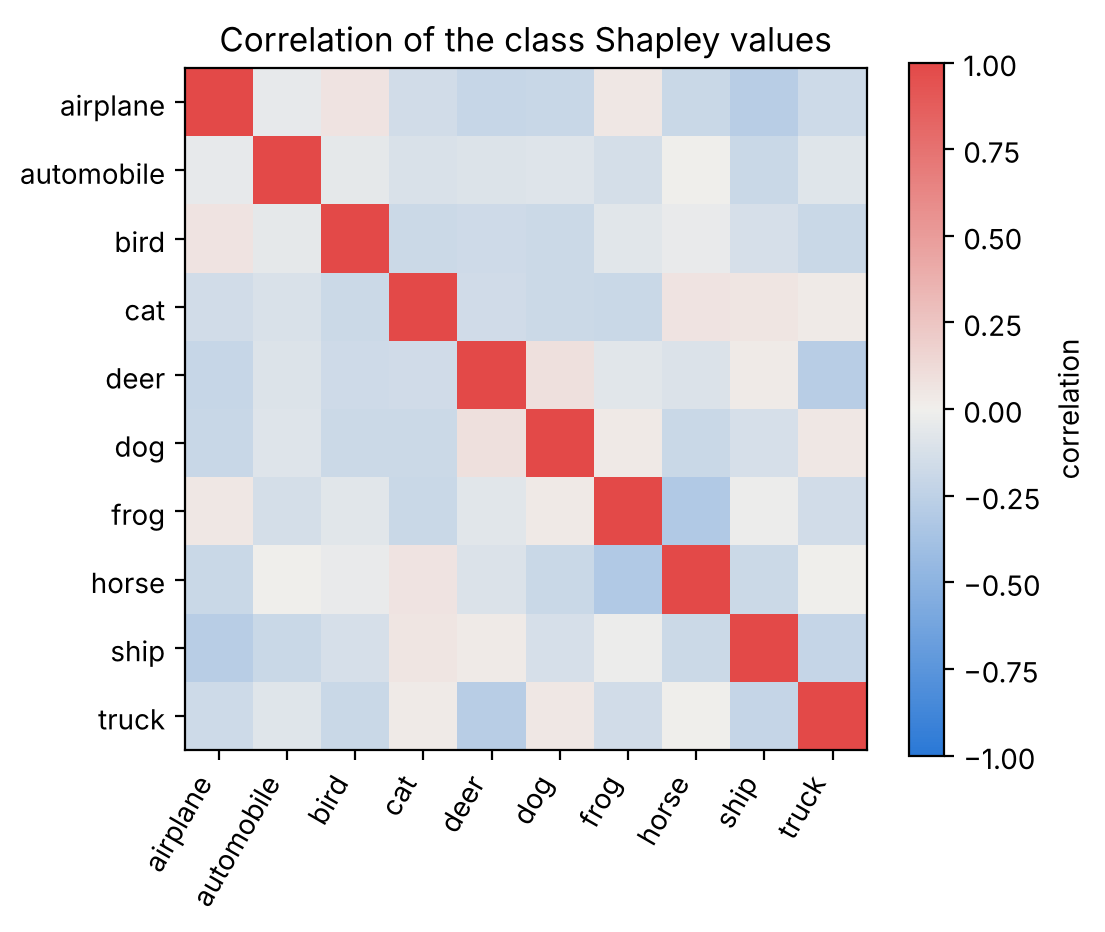

In [6]:
informative = class_phi.abs().sum(1) > 0
print(f"{informative.sum()} neurons with a nonzero value for at least one class")
correlation = torch.corrcoef(class_phi[informative].T)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
image = ax.imshow(correlation, cmap=diverging, norm=TwoSlopeNorm(0, -1, 1))
ax.set_xticks(range(10), CLASSES, rotation=60, ha="right")
ax.set_yticks(range(10), CLASSES)
ax.grid(False)
fig.colorbar(image, ax=ax, label="correlation")
ax.set_title("Correlation of the class Shapley values")
plt.show()

Most of the valuable neurons serve one or two classes, and many help some classes while hurting others: neuron 37 lowers the loss of truck and horse and raises that of frog, ship and airplane. The class values are close to uncorrelated, between about −0.3 and 0.1. In this network, each class relies mostly on its own neurons, and the values of visually similar classes, such as automobile and truck or cat and dog, are no more correlated than those of other pairs.

## 4. Which classes a global pruning hurts

Test accuracy per class of the parent network with only the top $k$ neurons of the global ranking active, without retraining.

In [7]:
columns = {}
for k in (16, 32, 64, 128):
    predictions = predict(parent, data.test, neuron_mask=to_mask(top_k(global_phi, k), 128))
    columns[f"k = {k}"] = [100 * (predictions[data.test.labels == c] == c).float().mean().item()
                           for c in range(10)]
per_class = pd.DataFrame(columns, index=CLASSES)
per_class["loss from 128 to 16"] = per_class["k = 128"] - per_class["k = 16"]
per_class.sort_values("loss from 128 to 16", ascending=False).round(1)

,k = 16,k = 32,k = 64,k = 128,loss from 128 to 16
airplane,10.6,70.2,76.5,82.2,71.6
truck,32.2,79.9,82.2,79.9,47.7
ship,39.5,41.8,77.0,79.8,40.3
dog,36.8,39.9,73.5,71.2,34.4
bird,18.5,33.7,59.2,52.5,34.0
deer,39.2,56.0,62.0,65.3,26.1
frog,67.3,83.0,77.5,79.0,11.7
horse,79.3,68.2,76.1,76.7,-2.6
cat,49.4,42.9,44.4,44.7,-4.7
automobile,91.1,89.0,79.8,81.1,-10.0


Here, the global ranking serves the classes unevenly. With the top 16 neurons, airplane falls from 82% to 11% and truck from 80% to 32%, while automobile rises from 81% to 91% and horse and cat gain a few points. Ship only recovers with 64 neurons. To keep a given class, the class-conditional values show which neurons it needs.